# 72-step water-level forecasting

The notebook uses lagged water levels as predictors, evaluates fixed models with time-series cross-fitting, and tunes XGBoost with randomized search.


In [2]:
# Things to add: Try adding  a seasonal variable (f.e. month as predictor), use lstm (scale data first)


from scipy.stats import randint, uniform
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
import numpy as np
import pandas as pd

DATA_PATH = '../data/final/pegel_weather_6_hourly_lags_forecast_72h.parquet'
N_SPLITS = 5
RANDOM_STATE = 42

def load_data(data_path, predictor_pattern='water_level_lag_'):
    df = pd.read_parquet(data_path).sort_values('timestamp').reset_index(drop=True)
    predictor_columns = [column for column in df.columns if predictor_pattern in column]
    if not predictor_columns:
        raise ValueError(f'No predictors found for pattern {predictor_pattern!r}.')
    X = df[predictor_columns].apply(pd.to_numeric, errors='coerce')
    X = X.loc[:, X.notna().any(axis=0)]
    y = np.stack(df['water_levels'].to_numpy())
    if y.ndim != 2 or y.shape[1] != 73:
        raise ValueError(f'Expected water_levels shape (n_rows, 73), got {y.shape}.')
    if not np.allclose(y[:, 0], df['water_level'].to_numpy(), equal_nan=False):
        raise ValueError('The first water_levels value is not the current water_level.')
    y = y[:, 1:]
    valid_rows = np.isfinite(y).all(axis=1)
    X = X.loc[valid_rows].reset_index(drop=True)
    return X, y[valid_rows]


In [2]:
def evaluate_cross_fitted_model(model, model_name, X, y, n_splits=N_SPLITS, gap=0):
    """Evaluate a supplied estimator or pipeline with chronological cross-fitting."""
    predictions = np.full(y.shape, np.nan, dtype=float)
    splitter = TimeSeriesSplit(n_splits=n_splits, gap=gap)
    for fold, (train_idx, validation_idx) in enumerate(splitter.split(X), start=1):
        fold_model = clone(model)
        fold_model.fit(X.iloc[train_idx], y[train_idx])
        predictions[validation_idx] = fold_model.predict(X.iloc[validation_idx])
        print(f'{model_name}: completed fold {fold}/{n_splits}')
    evaluated = np.isfinite(predictions).all(axis=1)
    actual, predicted = y[evaluated], predictions[evaluated]
    errors = actual - predicted
    pooled_mse = mean_squared_error(actual.ravel(), predicted.ravel())
    metrics = pd.DataFrame([{'model': model_name, 'validation_rows': len(actual), 'mse': pooled_mse, 'rmse': np.sqrt(pooled_mse), 'mae': mean_absolute_error(actual.ravel(), predicted.ravel())}])
    horizon_metrics = pd.DataFrame({'model': model_name, 'horizon': np.arange(1, y.shape[1] + 1), 'mse': np.mean(errors ** 2, axis=0), 'rmse': np.sqrt(np.mean(errors ** 2, axis=0)), 'mae': np.mean(np.abs(errors), axis=0)})
    return predictions, metrics, horizon_metrics


In [3]:
def tune_hyperparameters(model, param_distributions, X_train, y_train, n_iter=10, n_splits=N_SPLITS, gap=72, random_state=RANDOM_STATE):
    """Tune a pipeline and return the MSE-selected model and CV results."""
    search = RandomizedSearchCV(estimator=model, param_distributions=param_distributions, n_iter=n_iter, scoring={'mse': 'neg_mean_squared_error', 'mae': 'neg_mean_absolute_error'}, refit='mse', cv=TimeSeriesSplit(n_splits=n_splits, gap=gap), n_jobs=-1, pre_dispatch='n_jobs', random_state=random_state, return_train_score=False, verbose=1)
    search.fit(X_train, y_train)
    cv_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_mse').reset_index(drop=True)
    return search.best_estimator_, cv_results


In [6]:
X, y = load_data(DATA_PATH)
linear_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('linear', LinearRegression())])
xgb_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('xgb', XGBRegressor(objective='reg:squarederror', tree_method='hist', multi_strategy='multi_output_tree', n_jobs=1, random_state=RANDOM_STATE))])
linear_oof, linear_metrics, linear_horizon_metrics = evaluate_cross_fitted_model(linear_pipeline, 'Linear regression', X, y)
xgb_oof, xgb_metrics, xgb_horizon_metrics = evaluate_cross_fitted_model(xgb_pipeline, 'XGBoost', X, y)
display(pd.concat([linear_metrics, xgb_metrics], ignore_index=True))
horizon_metrics = pd.concat([linear_horizon_metrics, xgb_horizon_metrics], ignore_index=True)
display(horizon_metrics)


Linear regression: completed fold 1/5
Linear regression: completed fold 2/5
Linear regression: completed fold 3/5
Linear regression: completed fold 4/5
Linear regression: completed fold 5/5
XGBoost: completed fold 1/5
XGBoost: completed fold 2/5
XGBoost: completed fold 3/5
XGBoost: completed fold 4/5
XGBoost: completed fold 5/5


,model,validation_rows,mse,rmse,mae
0,Linear regression,429530,585.709610,24.201438,12.979620
1,XGBoost,429530,556.538057,23.591059,12.324219


,model,horizon,mse,rmse,mae
0,Linear regression,1,34.110248,5.840398,3.387125
1,Linear regression,2,45.434102,6.740482,3.846627
2,Linear regression,3,57.683834,7.594987,4.228033
3,Linear regression,4,73.149496,8.552748,4.685859
4,Linear regression,5,90.878013,9.532996,5.155266
...,...,...,...,...,...
139,XGBoost,68,843.250596,29.038777,16.868139
140,XGBoost,69,847.803920,29.117073,16.942745
141,XGBoost,70,852.316964,29.194468,17.017401
142,XGBoost,71,856.845650,29.271926,17.094355


Text(0, 0.5, 'MAE')

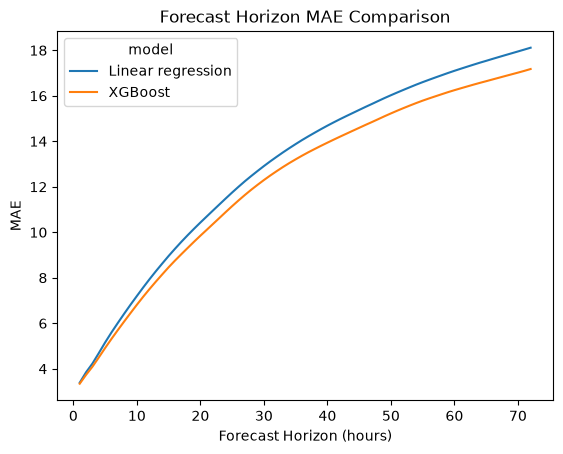

In [8]:
# Visualize the horizon metrics for both models
import matplotlib.pyplot as plt
import seaborn as sns


p = sns.lineplot(data=horizon_metrics, x='horizon', y='mae', hue='model')
p.set_title('Forecast Horizon MAE Comparison')
p.set_xlabel('Forecast Horizon (hours)')
p.set_ylabel('MAE')

In [13]:
import joblib

holdout_size = int(len(X) * 0.2)
X_train, X_test = X.iloc[:-holdout_size], X.iloc[-holdout_size:]
y_train, y_test = y[:-holdout_size], y[-holdout_size:]
param_distributions = {'xgb__n_estimators': randint(50, 201), 'xgb__max_depth': randint(3, 10), 'xgb__learning_rate': uniform(0.01, 0.29), 'xgb__subsample': uniform(0.5, 0.5), 'xgb__colsample_bytree': uniform(0.5, 0.5)}
best_xgb_model, xgb_cv_results = tune_hyperparameters(xgb_pipeline, param_distributions, X_train, y_train)
joblib.dump(best_xgb_model, '../out/models/best_xgb_model.joblib')
display(xgb_cv_results[['params', 'mean_test_mse', 'rank_test_mse', 'mean_test_mae', 'rank_test_mae']])
test_predictions = best_xgb_model.predict(X_test)
print(f'Chronological holdout MSE: {mean_squared_error(y_test.ravel(), test_predictions.ravel()):.6f}')
print(f'Chronological holdout MAE: {mean_absolute_error(y_test.ravel(), test_predictions.ravel()):.6f}')


Fitting 5 folds for each of 10 candidates, totalling 50 fits


/Users/laurensmauz/.local/lib/python3.15/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,params,mean_test_mse,rank_test_mse,mean_test_mae,rank_test_mae
0,"{'xgb__colsample_bytree': 0.9299702033681603, ...",-595.213665,1,-12.678810,5
1,"{'xgb__colsample_bytree': 0.5780093202212182, ...",-595.798318,2,-12.662459,4
2,"{'xgb__colsample_bytree': 0.9828160165372797, ...",-597.779605,3,-12.683047,6
3,"{'xgb__colsample_bytree': 0.5714334089609704, ...",-598.087130,4,-12.649203,2
4,"{'xgb__colsample_bytree': 0.8925879806965068, ...",-598.429153,5,-12.653940,3
5,"{'xgb__colsample_bytree': 0.6872700594236812, ...",-600.919707,6,-12.647022,1
6,"{'xgb__colsample_bytree': 0.8421165132560784, ...",-603.419747,7,-12.699016,7
7,"{'xgb__colsample_bytree': 0.6999304858576277, ...",-636.031134,8,-14.495990,8
8,"{'xgb__colsample_bytree': 0.8058265802441404, ...",-697.329423,9,-15.942422,9
9,"{'xgb__colsample_bytree': 0.9692763545078751, ...",-825.811124,10,-18.692316,10


Chronological holdout MSE: 391.871002
Chronological holdout MAE: 10.916377
